# Activity 5 — Text Extraction
License plate: read the plate number (OCR) and tell the vehicle type from the plate colors.

Tesseract 5.4.0.20240606 - image size: 640x550


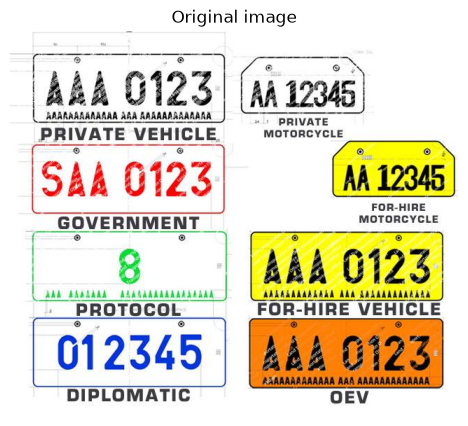

In [1]:
import os
import shutil
from pathlib import Path
from collections import Counter

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pytesseract

# Tesseract: PATH, TESSERACT_CMD, or the default Windows install
tesseract_cmd = os.environ.get('TESSERACT_CMD') or shutil.which('tesseract')
if not tesseract_cmd:
    windows_path = Path(os.environ.get('ProgramFiles', 'C:/Program Files')) / 'Tesseract-OCR' / 'tesseract.exe'
    tesseract_cmd = str(windows_path) if windows_path.is_file() else None
if not tesseract_cmd:
    raise RuntimeError('Install Tesseract OCR, then add it to PATH or set TESSERACT_CMD.')
pytesseract.pytesseract.tesseract_cmd = tesseract_cmd

# Load image
IMAGE_PATH = 'license.jpg'
image = cv2.imread(IMAGE_PATH)
if image is None:
    raise FileNotFoundError("Image not found.")

print(f'Tesseract {pytesseract.get_tesseract_version()} - image size: {image.shape[1]}x{image.shape[0]}')

plt.figure(figsize=(8, 5))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title('Original image')
plt.axis('off')
plt.show()

Find the characters: crop the plate edges, Otsu threshold, then keep tall, narrow contours (skips the border, holes and small marks).

In [2]:
def find_characters(plate):
    """Return the cropped plate, its binary mask, and the sorted character boxes."""
    height, width = plate.shape[:2]
    # cut away the plate border
    crop = plate[int(height * 0.10):int(height * 0.90), int(width * 0.04):int(width * 0.96)]

    gray = cv2.GaussianBlur(cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY), (3, 3), 0)
    _, binary = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    if cv2.countNonZero(binary) < binary.size / 2:   # make the background white
        binary = cv2.bitwise_not(binary)

    h, w = binary.shape
    contours, _ = cv2.findContours(255 - binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    boxes = []
    for contour in contours:
        x, y, bw, bh = cv2.boundingRect(contour)
        if h * 0.35 <= bh <= h * 0.95 and w * 0.02 <= bw <= w * 0.30:
            boxes.append((x, y, bw, bh))
    return crop, binary, sorted(boxes)

Classify the plate by color. The background tells white, yellow or orange. If the background is white, the color of the characters decides.

In [3]:
CATEGORIES = {
    'Private':    '#222222',
    'Government': '#d62828',
    'Protocol':   '#2a9d3f',
    'Diplomatic': '#1d4fb8',
    'For-Hire':   '#f4c20d',
    'OEV':        '#f77f00',
}

def classify_plate(crop, binary, boxes):
    """Return (category, background color name, character color name)."""
    hsv = cv2.cvtColor(crop, cv2.COLOR_BGR2HSV)

    char_mask = np.zeros(binary.shape, np.uint8)
    for x, y, w, h in boxes:
        char_mask[y:y + h, x:x + w] = 255
    ink = hsv[(char_mask == 255) & (binary == 0)]      # character pixels
    paper = hsv[binary == 255]                          # plate background pixels
    (bg_h, bg_s, _), (ink_h, ink_s, ink_v) = np.median(paper, 0), np.median(ink, 0)

    # colored background
    if bg_s > 100:
        if 8 <= bg_h < 22:
            return 'OEV', 'orange', 'black'
        if 22 <= bg_h <= 38:
            return 'For-Hire', 'yellow', 'black'

    # white background: the character color decides
    if ink_v < 70 or ink_s < 60:
        ink_name = 'black'
    elif ink_h < 10 or ink_h > 170:
        ink_name = 'red'
    elif 35 <= ink_h <= 85:
        ink_name = 'green'
    elif 95 <= ink_h <= 130:
        ink_name = 'blue'
    else:
        ink_name = 'unknown'
    category = {'black': 'Private', 'red': 'Government', 'green': 'Protocol',
                'blue': 'Diplomatic'}.get(ink_name, 'Unknown')
    return category, 'white', ink_name

Read the text: OCR each character several ways, take the majority vote, then group letters and digits at the widest gap.

In [4]:
LETTERS = 'ABCDEFGHIJKLMNOPQRSTUVWXYZ'
DIGITS = '0123456789'

def read_character(binary, box, whitelist):
    """Vote across page modes, padding, and sizes to stabilize one character."""
    x, y, w, h = box
    glyph = binary[y:y + h, x:x + w]
    votes = Counter()
    for size in (100, 140):
        resized = cv2.resize(glyph, None, fx=size / h, fy=size / h, interpolation=cv2.INTER_CUBIC)
        for pad in (20, 35, 50):
            padded = cv2.copyMakeBorder(resized, pad, pad, pad, pad, cv2.BORDER_CONSTANT, value=255)
            _, padded = cv2.threshold(padded, 127, 255, cv2.THRESH_BINARY)
            for psm in (8, 10, 13):
                config = f'--psm {psm} -c tessedit_char_whitelist={whitelist}'
                text = pytesseract.image_to_string(padded, config=config).strip()
                if text and text[0] in whitelist:
                    votes[text[0]] += 1
    return votes.most_common(1)[0][0] if votes else '?'

def read_plate(binary, boxes):
    """Letters come before the widest gap, digits after it. No wide gap = digits only."""
    if len(boxes) < 2:
        return ''.join(read_character(binary, b, LETTERS + DIGITS) for b in boxes)
    gaps = [boxes[i + 1][0] - (boxes[i][0] + boxes[i][2]) for i in range(len(boxes) - 1)]
    if max(gaps) > 1.6 * max(np.median(gaps), 1):
        split = int(np.argmax(gaps)) + 1
        letters = ''.join(read_character(binary, b, LETTERS) for b in boxes[:split])
        digits = ''.join(read_character(binary, b, DIGITS) for b in boxes[split:])
        return f'{letters} {digits}'
    return ''.join(read_character(binary, b, DIGITS) for b in boxes)

def character_strip(binary, boxes):
    """Selected characters only, on white paper, for display."""
    clean = np.full_like(binary, 255)
    for x, y, w, h in boxes:
        clean[y:y + h, x:x + w] = binary[y:y + h, x:x + w]
    left, right = min(b[0] for b in boxes), max(b[0] + b[2] for b in boxes)
    top, bottom = min(b[1] for b in boxes), max(b[1] + b[3] for b in boxes)
    return cv2.copyMakeBorder(clean[top:bottom, left:right], 20, 20, 20, 20, cv2.BORDER_CONSTANT, value=255)

def recognize_plate(img):
    crop, binary, boxes = find_characters(img)
    if not boxes:
        return {'plate': '[none]', 'category': 'Unknown', 'background': '-', 'characters': '-',
                'image': img, 'crop': crop, 'boxes': [], 'ocr_input': binary}
    category, background, ink = classify_plate(crop, binary, boxes)
    return {'plate': read_plate(binary, boxes), 'category': category, 'background': background,
            'characters': ink, 'image': img, 'crop': crop, 'boxes': boxes,
            'ocr_input': character_strip(binary, boxes)}

Run on the image and show each processing stage.

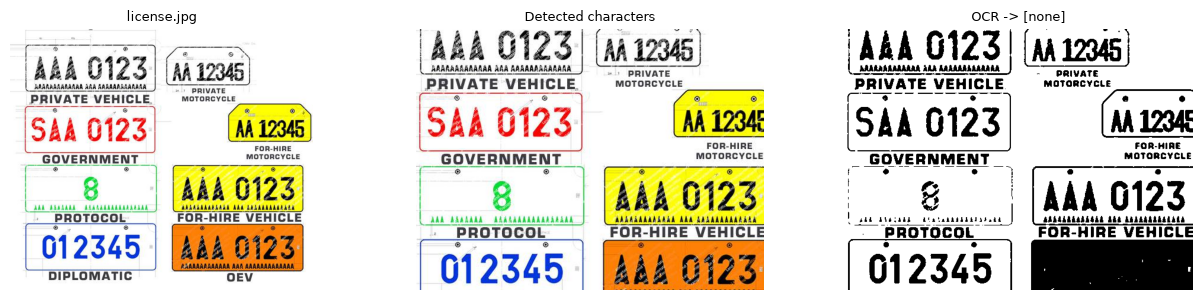

In [5]:
result = recognize_plate(image)

annotated = cv2.cvtColor(result['crop'], cv2.COLOR_BGR2RGB)
for x, y, w, h in result['boxes']:
    cv2.rectangle(annotated, (x, y), (x + w, y + h), (0, 170, 60), 2)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.1))
axes[0].imshow(cv2.cvtColor(result['image'], cv2.COLOR_BGR2RGB)); axes[0].set_title(IMAGE_PATH, fontsize=9)
axes[1].imshow(annotated);                                       axes[1].set_title('Detected characters', fontsize=9)
axes[2].imshow(result['ocr_input'], cmap='gray');                axes[2].set_title(f"OCR -> {result['plate']}", fontsize=9)
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

Final results.

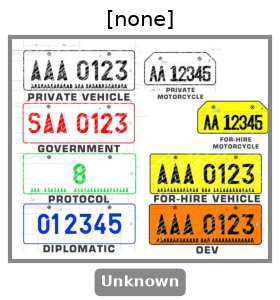

File,Plate number,Vehicle type,Background,Characters
license.jpg,[none],Unknown,-,-


In [6]:
color = CATEGORIES.get(result['category'], '#888888')

fig, ax = plt.subplots(1, 1, figsize=(5, 3.1))
ax.imshow(cv2.cvtColor(result['image'], cv2.COLOR_BGR2RGB))
ax.set_title(result['plate'], fontsize=15, pad=8)
ax.set_xlabel(result['category'], fontsize=11, fontweight='bold', color='white',
              bbox=dict(boxstyle='round,pad=0.4', fc=color, ec='none'), labelpad=10)
ax.set_xticks([]); ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_edgecolor(color); spine.set_linewidth(3)
plt.tight_layout()
plt.show()

summary = pd.DataFrame([{'File': IMAGE_PATH, 'Plate number': result['plate'],
                         'Vehicle type': result['category'],
                         'Background': result['background'], 'Characters': result['characters']}])
summary.style.hide(axis='index').set_properties(**{'text-align': 'left'})

OCR can confuse similar glyphs (for example 0 and 6, or O and Q), so check the plate number against the image. A frontal, cropped plate is assumed.